# Collecte des données MaPrimeRénov’

## Objectif

Collecter des données sur les dossiers MaPrimeRénov’ afin
de contextualiser l’activité de rénovation aidée en Île-de-France
et dans le Val-d’Oise.

Les données proviennent des bilans trimestriels publiés
par la DRIHL et la DRIEAT.

Elles complètent l’analyse territoriale fondée sur les DPE,
l’INSEE et les établissements RGE.
Les données sont régionales et départementales :
elles ne permettent pas une analyse des 12 communes ciblées.

## Méthode

Les informations disponibles dans les pages web sont extraites
avec Python. Le détail départemental du deuxième trimestre 2025,
absent de la transcription HTML, est ajouté manuellement
à partir du PDF officiel.

Le fichier produit contient les périodes, les territoires,
les nombres de dossiers et le mode de collecte.

In [2]:
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd

## Vérification de l’accès à une publication

Un premier appel permet de vérifier que la page est accessible.

- `requests` récupère le contenu de la page.
- Le code HTTP 200 indique que la requête a réussi.
- Cette vérification confirme l’accès à la page,
  mais pas encore la bonne extraction des données.

In [3]:
url_test = "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-4e-trimestre-2025-les-chiffres-de-la-a1490.html"

response_test = requests.get(url_test)

if response_test.status_code == 200:
    print("Connexion réussie - code 200")
else:
    print("Erreur de connexion :", response_test.status_code)

Connexion réussie - code 200


## Publications et territoires retenus

La collecte porte sur huit publications :
- Les quatre trimestres de 2024.
- Les deuxième, troisième et quatrième trimestres de 2025.
- Les premier et deuxième trimestres de 2026.

Le premier trimestre 2025 n’est pas inclus dans cette collecte.
La série ne permet donc pas de calculer un total annuel 2025 complet.

Les publications fournissent des totaux régionaux et,
pour certaines périodes, un détail par département.

**Repère :** l’absence d’une période ou d’un détail territorial
dans le fichier ne correspond pas à une valeur de zéro.

In [4]:
pages_mpr = [
    {
        "annee": 2024,
        "trimestre": "T1",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-1er-trimestre-2024-les-chiffres-de-la-a1327.html"
    },
    {
        "annee": 2024,
        "trimestre": "T2",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-2e-trimestre-2024-les-chiffres-de-la-a1353.html"
    },
    {
        "annee": 2024,
        "trimestre": "T3",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-3e-trimestre-2024-les-chiffres-de-la-a1365.html"
    },
    {
        "annee": 2024,
        "trimestre": "T4",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-4e-trimestre-2024-les-chiffres-de-la-a1378.html"
    },
    {
        "annee": 2025,
        "trimestre": "T2",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-2e-trimestre-2025-les-chiffres-de-la-a1437.html"
    },
    {
        "annee": 2025,
        "trimestre": "T3",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-3e-trimestre-2025-les-chiffres-de-la-a1470.html"
    },
    {
        "annee": 2025,
        "trimestre": "T4",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-4e-trimestre-2025-les-chiffres-de-la-a1490.html"
    },
    {
        "annee": 2026,
        "trimestre": "T1",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-1er-trimestre-2026-les-chiffres-de-la-a1516.html"
    },
        {
        "annee": 2026,
        "trimestre": "T2",
        "url": "https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-2e-trimestre-2026-les-chiffres-de-la-a1546.html"
    }
]

In [5]:
departements = {
    "75": "Paris",
    "77": "Seine-et-Marne",
    "78": "Yvelines",
    "91": "Essonne",
    "92": "Hauts-de-Seine",
    "93": "Seine-Saint-Denis",
    "94": "Val-de-Marne",
    "95": "Val-d'Oise"
}

## Extraction web

La fonction récupère chaque page, isole la rubrique MaPrimeRénov’
et recherche les nombres de dossiers régionaux et départementaux.

La rubrique est délimitée pour éviter de récupérer les chiffres
d’un autre dispositif.

In [6]:
def scraper_mpr(url, annee, trimestre):

    # Récupération et lecture de la page
    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")
    texte = soup.get_text(" ", strip=True)

    # Uniformiser les apostrophes
    texte = texte.replace("’", "'")

    # Délimiter uniquement la partie MaPrimeRénov' individuelle
    debut = texte.find("LA RÉNOVATION DE LOGEMENTS PARC PRIVÉ INDIVIDUEL")
    fin = texte.find(
    "LA RÉNOVATION DE LOGEMENTS",
    debut + len("LA RÉNOVATION DE LOGEMENTS PARC PRIVÉ INDIVIDUEL")
)
    if debut == -1:
        print("Rubrique non trouvée :", annee, trimestre)
        return []

    # Si le titre suivant n'est pas trouvé, on garde la suite du texte
    section = texte[debut:fin] if fin != -1 else texte[debut:]

    resultats = []

    # Recherche du total Île-de-France
    idf = re.search(
        r"En Île-de-France\s*:?\s*([\d\s]+)\s+dossiers",
        section
    )

    if idf:
        resultats.append({
            "annee": annee,
            "trimestre": trimestre,
            "niveau": "region",
            "code_territoire": "11",
            "territoire": "Île-de-France",
            "dossiers_mpr": int(idf.group(1).replace(" ", ""))
        })

    # Recherche automatique des départements
    for code, nom in departements.items():

        motif = rf"([\d\s]+)\s+(?:à|en|dans(?: le| la| les)?)\s+{re.escape(nom)}"
        resultat = re.search(motif, section, re.IGNORECASE)

        if resultat:
            resultats.append({
                "annee": annee,
                "trimestre": trimestre,
                "niveau": "departement",
                "code_territoire": code,
                "territoire": nom,
                "dossiers_mpr": int(resultat.group(1).replace(" ", ""))
            })

    return resultats

### Test sur une publication

Tester l’extraction sur le T4 2025 avant de lancer la collecte complète.

In [7]:
test_t4_2025 = scraper_mpr(
    pages_mpr[6]["url"],
    2025,
    "T4"
)

test_t4_2025

[{'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'region',
  'code_territoire': '11',
  'territoire': 'Île-de-France',
  'dossiers_mpr': 4306},
 {'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'departement',
  'code_territoire': '75',
  'territoire': 'Paris',
  'dossiers_mpr': 38},
 {'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'departement',
  'code_territoire': '77',
  'territoire': 'Seine-et-Marne',
  'dossiers_mpr': 1238},
 {'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'departement',
  'code_territoire': '78',
  'territoire': 'Yvelines',
  'dossiers_mpr': 520},
 {'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'departement',
  'code_territoire': '91',
  'territoire': 'Essonne',
  'dossiers_mpr': 707},
 {'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'departement',
  'code_territoire': '92',
  'territoire': 'Hauts-de-Seine',
  'dossiers_mpr': 99},
 {'annee': 2025,
  'trimestre': 'T4',
  'niveau': 'departement',
  'code_territoire': '93',
  'territoire': 'Seine-Saint-Denis',

In [8]:
resultats_mpr = []

for page in pages_mpr:

    resultats = scraper_mpr(
        page["url"],
        page["annee"],
        page["trimestre"]
    )

    resultats_mpr.extend(resultats)

len(resultats_mpr)

41

### Mise en tableau des résultats

Créer le DataFrame et afficher les données collectées.

In [9]:
df_mpr = pd.DataFrame(resultats_mpr)

df_mpr

,annee,trimestre,niveau,code_territoire,territoire,dossiers_mpr
0,2024,T1,region,11,Île-de-France,8990
1,2024,T2,region,11,Île-de-France,6611
2,2024,T3,region,11,Île-de-France,4763
3,2024,T4,region,11,Île-de-France,5222
4,2025,T2,region,11,Île-de-France,4682
5,2025,T3,region,11,Île-de-France,4092
6,2025,T3,departement,75,Paris,80
7,2025,T3,departement,77,Seine-et-Marne,1194
8,2025,T3,departement,78,Yvelines,557
9,2025,T3,departement,91,Essonne,688


In [10]:
df_mpr.shape

(41, 6)

### Vérification des territoires disponibles

Compter les lignes par trimestre :
- 1 ligne : le total régional uniquement.
- 9 lignes : le total régional et les huit départements.

Le détail départemental du T2 2025 sera ajouté depuis le PDF officiel.

In [11]:
df_mpr.groupby(["annee", "trimestre"]).size()

annee  trimestre
2024   T1           1
       T2           1
       T3           1
       T4           1
2025   T2           1
       T3           9
       T4           9
2026   T1           9
       T2           9
dtype: int64

## Complément manuel

Le détail départemental T2 2025, absent du HTML, est saisi
depuis le PDF officiel. `source_collecte` distingue ce complément
des valeurs extraites automatiquement.

Source :
https://www.drihl.ile-de-france.developpement-durable.gouv.fr/bilan-2e-trimestre-2025-les-chiffres-de-la-a1437.html

In [12]:
donnees_t2_2025 = [
    ["75", "Paris", 55],
    ["77", "Seine-et-Marne", 1452],
    ["78", "Yvelines", 624],
    ["91", "Essonne", 867],
    ["92", "Hauts-de-Seine", 145],
    ["93", "Seine-Saint-Denis", 506],
    ["94", "Val-de-Marne", 336],
    ["95", "Val-d'Oise", 697]
]

df_t2_2025 = pd.DataFrame(
    donnees_t2_2025,
    columns=["code_territoire", "territoire", "dossiers_mpr"]
)

df_t2_2025["annee"] = 2025
df_t2_2025["trimestre"] = "T2"
df_t2_2025["niveau"] = "departement"
df_t2_2025["source_collecte"] = "PDF officiel"

df_t2_2025

,code_territoire,territoire,dossiers_mpr,annee,trimestre,niveau,source_collecte
0,75,Paris,55,2025,T2,departement,PDF officiel
1,77,Seine-et-Marne,1452,2025,T2,departement,PDF officiel
2,78,Yvelines,624,2025,T2,departement,PDF officiel
3,91,Essonne,867,2025,T2,departement,PDF officiel
4,92,Hauts-de-Seine,145,2025,T2,departement,PDF officiel
5,93,Seine-Saint-Denis,506,2025,T2,departement,PDF officiel
6,94,Val-de-Marne,336,2025,T2,departement,PDF officiel
7,95,Val-d'Oise,697,2025,T2,departement,PDF officiel


Ajouter les huit départements du T2 2025 au tableau principal.

In [13]:
df_mpr = pd.concat(
    [df_mpr, df_t2_2025],
    ignore_index=True
)

Vérifier que le T2 2025 contient désormais neuf lignes.

In [14]:
df_mpr.groupby(["annee", "trimestre"]).size()

annee  trimestre
2024   T1           1
       T2           1
       T3           1
       T4           1
2025   T2           9
       T3           9
       T4           9
2026   T1           9
       T2           9
dtype: int64

### Origine des données

Les lignes ajoutées manuellement portent la mention « PDF officiel ».
Compléter les autres avec « scraping HTML ».

In [15]:
df_mpr["source_collecte"] = df_mpr["source_collecte"].fillna("scraping HTML")

In [16]:
df_mpr = df_mpr.sort_values(
    by=["annee", "trimestre", "niveau", "code_territoire"]
).reset_index(drop=True)

df_mpr

,annee,trimestre,niveau,code_territoire,territoire,dossiers_mpr,source_collecte
0,2024,T1,region,11,Île-de-France,8990,scraping HTML
1,2024,T2,region,11,Île-de-France,6611,scraping HTML
2,2024,T3,region,11,Île-de-France,4763,scraping HTML
3,2024,T4,region,11,Île-de-France,5222,scraping HTML
4,2025,T2,departement,75,Paris,55,PDF officiel
5,2025,T2,departement,77,Seine-et-Marne,1452,PDF officiel
6,2025,T2,departement,78,Yvelines,624,PDF officiel
7,2025,T2,departement,91,Essonne,867,PDF officiel
8,2025,T2,departement,92,Hauts-de-Seine,145,PDF officiel
9,2025,T2,departement,93,Seine-Saint-Denis,506,PDF officiel


### Contrôles avant export

Vérifier les dimensions, les valeurs manquantes et les doublons.

In [17]:
print("Dimensions :", df_mpr.shape)

print("\nValeurs manquantes :")
print(df_mpr.isna().sum())

print("\nDoublons :")
print(
    df_mpr.duplicated(
        subset=["annee", "trimestre", "niveau", "code_territoire"]
    ).sum()
)

Dimensions : (49, 7)

Valeurs manquantes :
annee              0
trimestre          0
niveau             0
code_territoire    0
territoire         0
dossiers_mpr       0
source_collecte    0
dtype: int64

Doublons :
0


### Export pour Power BI

Enregistrer le tableau contrôlé dans le fichier CSV utilisé par Power BI.

In [18]:
df_mpr.to_csv(
    "../Data/Output/maprimerenov_contexte.csv",
    index=False
)

## Contrôle de la collecte

Fichier exporté : 40 lignes, aucune valeur manquante
et aucun doublon sur la clé période–niveau–territoire.

La série est partielle : T1 2025 manque.
Ne pas additionner les totaux régionaux aux départements.

Les dossiers engagés ne correspondent pas nécessairement
à des travaux achevés. Vérifier les définitions des publications
avant toute comparaison entre périodes.

## Activité de rénovation aidée dans le Val-d’Oise

Comparer les nombres de dossiers collectés pour le département.
La série est partielle : elle décrit les périodes disponibles,
sans permettre une conclusion sur une tendance annuelle.

,Période,Nombre de dossiers
11,T2 2025,697
20,T3 2025,587
29,T4 2025,720
38,T1 2026,439
47,T2 2026,859


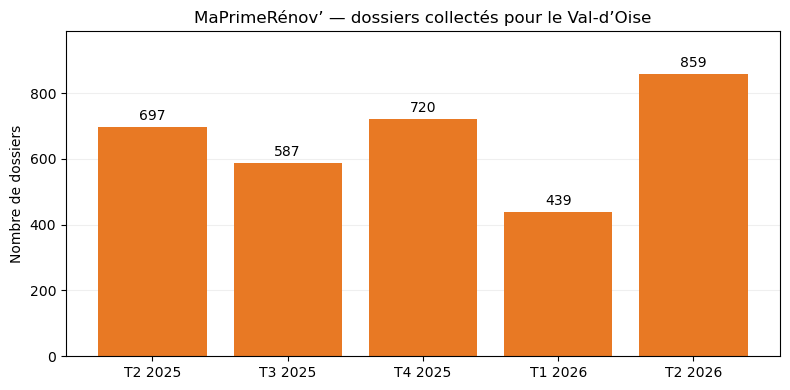

In [19]:
import matplotlib.pyplot as plt

# Retenir le département 95 uniquement, sans les totaux régionaux.
mpr_95 = df_mpr.loc[
    (df_mpr["niveau"] == "departement")
    & (df_mpr["code_territoire"].astype(str) == "95")
].copy()

# Trier les périodes et créer les libellés du graphique.
mpr_95 = mpr_95.sort_values(["annee", "trimestre"])
mpr_95["periode"] = (
    mpr_95["trimestre"] + " " + mpr_95["annee"].astype(str)
)

display(
    mpr_95[["periode", "dossiers_mpr"]]
    .rename(columns={
        "periode": "Période",
        "dossiers_mpr": "Nombre de dossiers"
    })
)

# Barres séparées : chaque valeur correspond à une période.
fig, ax = plt.subplots(figsize=(8, 4))

barres = ax.bar(
    mpr_95["periode"],
    mpr_95["dossiers_mpr"],
    color="#E87924"
)

ax.bar_label(barres, padding=3)
ax.set_title("MaPrimeRénov’ — dossiers collectés pour le Val-d’Oise")
ax.set_ylabel("Nombre de dossiers")
ax.set_ylim(0, mpr_95["dossiers_mpr"].max() * 1.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Lecture et intérêt commercial

### Lecture et intérêt commercial

Le Val-d’Oise compte 859 dossiers engagés au T2 2026,
contre 439 au trimestre précédent et 697 au T2 2025.

La publication signale un possible effet de rattrapage après
la réouverture tardive du guichet de l’Anah en février 2026.
La hausse ne traduit donc pas nécessairement une progression
équivalente de la demande.

Pour un distributeur, suivre cet indicateur pourrait aider
à préparer les campagnes et les animations auprès des professionnels.

La série reste courte. Il faut prolonger le suivi et confirmer
la comparabilité des périodes avant de conclure à une tendance
ou à une saisonnalité.